# 1. Setup and data extraction

In [162]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations
from statsmodels.stats.multitest import multipletests

In [163]:
with open("metrics/first10x10run_6-test-iters30.json") as json_file:
    data00 = json.load(json_file)

with open("metrics/first10x10run_65-test-iters30.json") as json_file:
    data05 = json.load(json_file)

with open("metrics/first10x10run_7-test-iters30.json") as json_file:
    data10 = json.load(json_file)

In [164]:
def makedf(data, condition):

    df = pd.DataFrame({
        "condition": condition,
        "obstacle": data["obstacles"],
        "agent_spawn": data["agents"],
        "alignment": data["avg_alignm_after_100"],
        "cohesion": data["avg_cohesi_after_100"],
        "diameter": data["avg_diamet_after_100"],
        "collisions": data["avg_collis_after_100"],
        "connectivity": data["avg_connec_after_100"],
        "phi": data["avg_phipxy_after_100"],
    })

    df["test_id"] = [f"{obstacle}_{agent_spawn}" for obstacle, agent_spawn in zip(df["obstacle"], df["agent_spawn"])]

    return df

In [165]:
dfs = []
dfs.append(makedf(data00, "Phi = 0.00"))
dfs.append(makedf(data05, "Phi = 0.05"))
dfs.append(makedf(data10, "Phi = 0.10"))
df = pd.concat(dfs, ignore_index=True)

# 2. Basic descriptive statistics

In [166]:
def bootstrap_conf_int(x):
    x = np.asarray(x)
    x = x[~np.isnan(x)]
    rng = np.random.default_rng(42)
    boot = np.empty(10000)
    for i in range(10000):
        sple = rng.choice(x, size=len(x), replace=True)
        boot[i] = np.mean(sple)
    return (np.percentile(boot, 2.5), np.percentile(boot, 97.5))

In [167]:
metrics = ["alignment", "cohesion", "diameter", "collisions", "connectivity", "phi"]
s = (df.groupby("condition")[metrics].agg(["mean", "std", "median"]).round(4))
print(s)

           alignment                 cohesion                 diameter  \
                mean     std  median     mean     std  median     mean   
condition                                                                
Phi = 0.00    0.9477  0.0275  0.9526   0.2504  0.0371  0.2428   0.5615   
Phi = 0.05    0.9311  0.0337  0.9319   0.2646  0.0433  0.2632   0.5645   
Phi = 0.10    0.9096  0.0349  0.9109   0.3211  0.0463  0.3234   0.6690   

                           collisions                 connectivity          \
               std  median       mean     std  median         mean     std   
condition                                                                    
Phi = 0.00  0.1045  0.5363     4.7758  1.2309  4.9631       1.0981  0.1172   
Phi = 0.05  0.1179  0.5558     3.5882  1.2263  3.5188       1.1053  0.1297   
Phi = 0.10  0.1062  0.6516     2.3206  1.0865  2.1112       1.2002  0.1516   

                        phi                   
            median     mean     std   m

In [168]:
for cond in ["Phi = 0.00", "Phi = 0.05", "Phi = 0.10"]:
    print(cond)
    subset = df[df["condition"] == cond]
    for metr in metrics:
        low, high = bootstrap_conf_int(subset[metr])
        print(
            f"{metr:12s}: "
            f"{subset[metr].mean():.4f} "
            f"[{low:.4f}, {high:.4f}]"
        )
    print()

Phi = 0.00
alignment   : 0.9477 [0.9421, 0.9531]
cohesion    : 0.2504 [0.2435, 0.2581]
diameter    : 0.5615 [0.5424, 0.5835]
collisions  : 4.7758 [4.5315, 5.0161]
connectivity: 1.0981 [1.0760, 1.1219]
phi         : 59.9521 [59.4574, 60.4367]

Phi = 0.05
alignment   : 0.9311 [0.9245, 0.9375]
cohesion    : 0.2646 [0.2566, 0.2736]
diameter    : 0.5645 [0.5431, 0.5895]
collisions  : 3.5882 [3.3497, 3.8292]
connectivity: 1.1053 [1.0809, 1.1316]
phi         : 60.3187 [59.8321, 60.8092]

Phi = 0.10
alignment   : 0.9096 [0.9026, 0.9164]
cohesion    : 0.3211 [0.3121, 0.3302]
diameter    : 0.6690 [0.6488, 0.6902]
collisions  : 2.3206 [2.1135, 2.5395]
connectivity: 1.2002 [1.1718, 1.2302]
phi         : 64.6311 [64.0993, 65.1735]



In [171]:
labels = {
    "Phi = 0.00": r"$\beta$ = 0.00",
    "Phi = 0.05": r"$\beta$ = 0.05",
    "Phi = 0.10": r"$\beta$ = 0.10"
}

/var/folders/tq/f7lcjhp564g26624rbp38l240000gn/T/ipykernel_32439/3158375064.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([labels.get(label.get_text(), label.get_text()) for label in ax.get_xticklabels()])
/var/folders/tq/f7lcjhp564g26624rbp38l240000gn/T/ipykernel_32439/3158375064.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([labels.get(label.get_text(), label.get_text()) for label in ax.get_xticklabels()])
/var/folders/tq/f7lcjhp564g26624rbp38l240000gn/T/ipykernel_32439/3158375064.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([labels.get(label.get_text(), label.get_text()) for label in ax.get_xticklabels()])
/var/folders/tq/f7lcjhp564g26624rbp38l240000gn/T/ipy

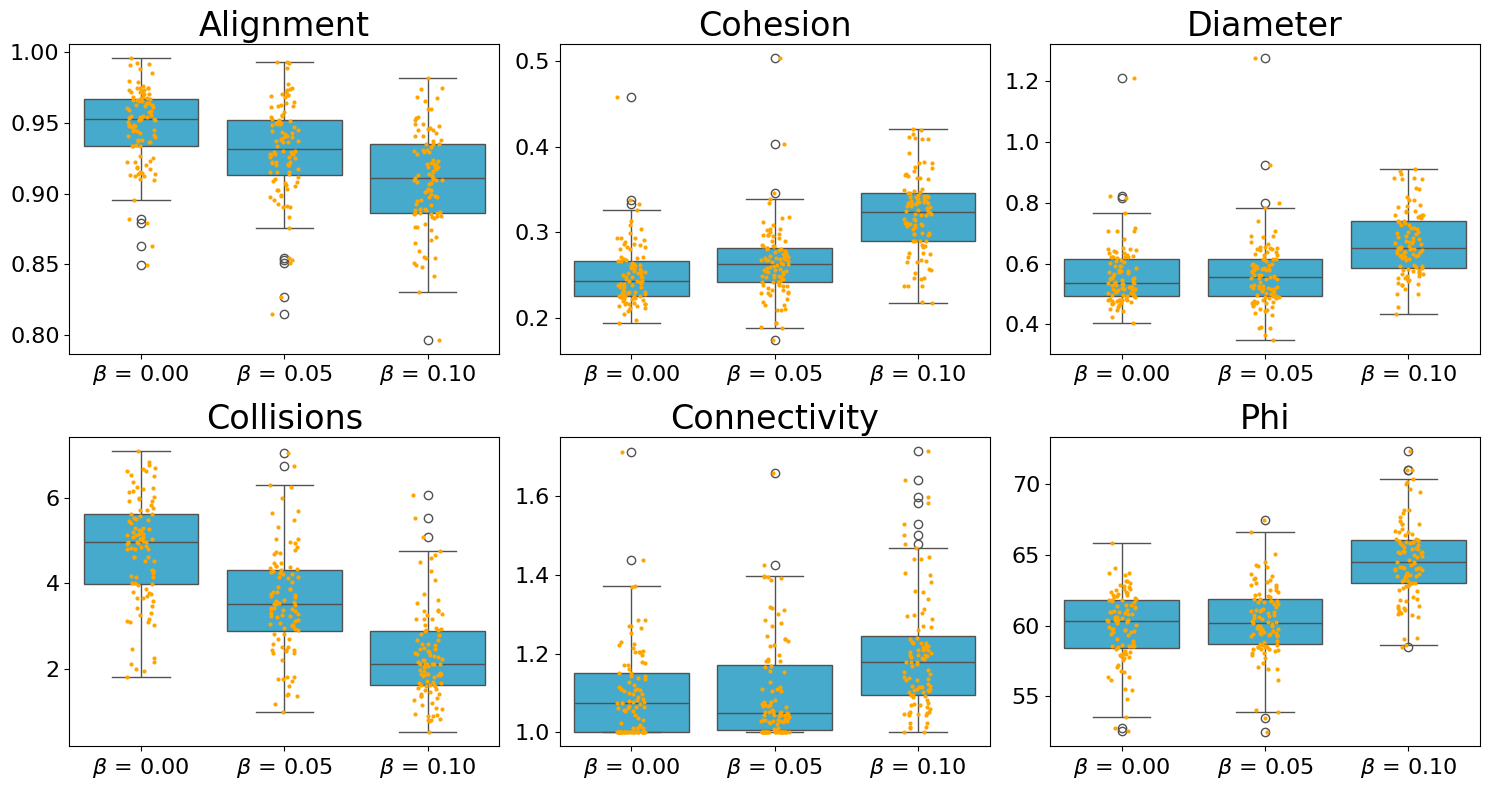

In [192]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, metr in zip(axes.flat, metrics):
    sns.boxplot(data=df, x="condition", y=metr, ax=ax, color="#2EB5E2")
    sns.stripplot(data=df, x="condition", y=metr, ax=ax, alpha=1.0, size=3, color="orange")
    ax.set_title(metr.capitalize(), fontsize=24)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelsize=16)
    ax.tick_params(axis="y", labelsize=16)
    ax.set_xticklabels([labels.get(label.get_text(), label.get_text()) for label in ax.get_xticklabels()])
plt.tight_layout()
plt.show()

# 3. Paired permutations test, CI for paired difference

In [145]:
def pair_perm_test(x, y):
    x = np.asarray(x)
    y = np.asarray(y)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    dif = y - x
    obs = np.mean(dif)
    rng = np.random.default_rng(42)

    nullmeans = np.empty(10000)
    for i in range(10000):
        signs = rng.choice([-1, 1], size=len(dif))
        nullmeans[i] = np.mean(dif * signs)

    p = (np.sum(np.abs(nullmeans) >= abs(obs)) + 1) / (10000 + 1)
    return obs, p

def pair_cohend(x, y):
    x = np.asarray(x)
    y = np.asarray(y)
    return (np.mean(y - x) / np.std(y - x, ddof=1))

def paired_bootstrap_ci(x, y):
    x = np.asarray(x)
    y = np.asarray(y)
    diff = y - x
    rng = np.random.default_rng(42)
    boot_means = []
    for _ in range(10000):
        sample = rng.choice(diff, size=len(diff), replace=True)
        boot_means.append(np.mean(sample))
    return np.percentile(boot_means, [2.5, 97.5])

In [146]:
wide = df.pivot(index="test_id", columns="condition", values=metrics)
conditions = ["Phi = 0.00", "Phi = 0.05", "Phi = 0.10"]

results = []
for metr in metrics:
    for c1, c2 in combinations(conditions, 2):
        x = (df[df["condition"] == c1].set_index("test_id")[metr])
        y = (df[df["condition"] == c2].set_index("test_id")[metr])
        comm_ord = x.index.intersection(y.index)
        x = x.loc[comm_ord]
        y = y.loc[comm_ord]
        diff, p = pair_perm_test(x, y)
        results.append({"metric": metr, "comparison": f"{c2} - {c1}", "mean_difference": diff, "p_raw": p})
results_df = pd.DataFrame(results)

results_df["p_fdr"] = multipletests(results_df["p_raw"], method="fdr_bh")[1]
results_df["significant"] = (results_df["p_fdr"] < 0.05)

effect_results = []
for metr in metrics:
    for c1, c2 in combinations(conditions, 2):
        x = (df[df["condition"] == c1].set_index("test_id")[metr])
        y = (df[df["condition"] == c2].set_index("test_id")[metr])
        comm_ord = x.index.intersection(y.index)
        x = x.loc[comm_ord]
        y = y.loc[comm_ord]
        effect_results.append({"metric": metr, "comparison": f"{c2} - {c1}", "cohens_d": pair_cohend(x, y)})
effect_df = pd.DataFrame(effect_results)

ci_results = []
for metr in metrics:
    for c1, c2 in combinations(conditions, 2):
        x = (df[df["condition"] == c1].set_index("test_id")[metr])
        y = (df[df["condition"] == c2].set_index("test_id")[metr])
        comm_ord = x.index.intersection(y.index)
        x = x.loc[comm_ord]
        y = y.loc[comm_ord]
        lo, hi = paired_bootstrap_ci(x, y)
        ci_results.append({"metric": metr, "comparison": f"{c2} - {c1}", "CI_low": lo, "CI_high": hi})
ci_df = pd.DataFrame(ci_results)

final_stats = (results_df.merge(effect_df, on=["metric", "comparison"]).merge(ci_df, on=["metric", "comparison"]))
print(final_stats)

          metric               comparison  mean_difference     p_raw  \
0      alignment  Phi = 0.05 - Phi = 0.00        -0.016628  0.000400   
1      alignment  Phi = 0.10 - Phi = 0.00        -0.038110  0.000100   
2      alignment  Phi = 0.10 - Phi = 0.05        -0.021483  0.000200   
3       cohesion  Phi = 0.05 - Phi = 0.00         0.014172  0.010699   
4       cohesion  Phi = 0.10 - Phi = 0.00         0.070685  0.000100   
5       cohesion  Phi = 0.10 - Phi = 0.05         0.056513  0.000100   
6       diameter  Phi = 0.05 - Phi = 0.00         0.002978  0.852015   
7       diameter  Phi = 0.10 - Phi = 0.00         0.107508  0.000100   
8       diameter  Phi = 0.10 - Phi = 0.05         0.104530  0.000100   
9     collisions  Phi = 0.05 - Phi = 0.00        -1.187600  0.000100   
10    collisions  Phi = 0.10 - Phi = 0.00        -2.455237  0.000100   
11    collisions  Phi = 0.10 - Phi = 0.05        -1.267637  0.000100   
12  connectivity  Phi = 0.05 - Phi = 0.00         0.007200  0.68

# 4. Analysis of Phi vs behaviour

In [147]:
bmap = {"Phi = 0.00": 0.00, "Phi = 0.05": 0.05, "Phi = 0.10": 0.10}
df["beta"] = df["condition"].map(bmap)

trend_results = []
for metr in metrics:
    rho, p = stats.spearmanr(df["beta"], df[metr])
    trend_results.append({"metric": metr, "spearman_rho": rho, "p_value": p})
trend_df = pd.DataFrame(trend_results)
print(trend_df)

         metric  spearman_rho       p_value
0     alignment     -0.454106  1.142408e-16
1      cohesion      0.590343  1.456950e-29
2      diameter      0.428226  8.274315e-15
3    collisions     -0.657849  1.429090e-38
4  connectivity      0.332971  3.364806e-09
5           phi      0.580491  2.024697e-28


In [148]:
phi_correlations = []

for cond in conditions:
    subset = df[df["condition"] == cond]
    for metr in ["alignment", "cohesion", "diameter", "collisions", "connectivity"]:
        rho, p = stats.spearmanr(subset["phi"], subset[metr])
        phi_correlations.append({"condition": cond, "metric": metr, "rho": rho, "p_value": p})
phicorr_df = pd.DataFrame(phi_correlations)
phicorr_df["p_fdr"] = multipletests(phicorr_df["p_value"], method="fdr_bh")[1]
print(phicorr_df)

     condition        metric       rho       p_value         p_fdr
0   Phi = 0.00     alignment  0.880732  1.415167e-33  2.122750e-32
1   Phi = 0.00      cohesion -0.623294  4.340173e-12  8.137824e-12
2   Phi = 0.00      diameter -0.530117  1.410465e-08  1.923361e-08
3   Phi = 0.00    collisions  0.646061  3.912366e-13  8.383642e-13
4   Phi = 0.00  connectivity -0.168756  9.326749e-02  9.326749e-02
5   Phi = 0.05     alignment  0.716184  5.477993e-17  4.108495e-16
6   Phi = 0.05      cohesion -0.534041  1.052916e-08  1.579374e-08
7   Phi = 0.05      diameter -0.385803  7.366390e-05  9.207988e-05
8   Phi = 0.05    collisions  0.699768  5.499575e-16  2.749787e-15
9   Phi = 0.05  connectivity -0.223414  2.545869e-02  2.727717e-02
10  Phi = 0.10     alignment  0.682820  5.080273e-15  1.905102e-14
11  Phi = 0.10      cohesion -0.646325  3.800167e-13  8.383642e-13
12  Phi = 0.10      diameter -0.579490  2.668904e-10  4.448173e-10
13  Phi = 0.10    collisions  0.660314  7.800884e-14  2.340265

In [149]:
rho, p = stats.spearmanr(df["phi"], df["collisions"])
print(f"Collision confounding - Phi vs collisions: rho={rho:.3f}, p={p:.4g}") # rho=-0.017, p=0.7649

Collision confounding - Phi vs collisions: rho=-0.017, p=0.7649


In [150]:
pooledphicorr = []
for metr in ["alignment", "cohesion", "diameter", "collisions", "connectivity"]:
    rho, p = stats.spearmanr(df["phi"], df[metr])
    pooledphicorr.append({"metric": metr, "rho": rho, "p_value": p})
print(pd.DataFrame(pooledphicorr))

         metric       rho   p_value
0     alignment  0.225657  0.000080
1      cohesion  0.046684  0.420441
2      diameter -0.008626  0.881718
3    collisions -0.017337  0.764903
4  connectivity  0.081168  0.160822


# 5. Comparing the same scenario across models

In [151]:
def pairdiff(metr, l, h):
    x = (df[df["condition"] == l].set_index("test_id")[metr])
    y = (df[df["condition"] == h].set_index("test_id")[metr])
    c = x.index.intersection(y.index)
    return y.loc[c] - x.loc[c]

In [152]:
for s1, s2 in [("Phi = 0.00", "Phi = 0.05"), ("Phi = 0.05", "Phi = 0.10"), ("Phi = 0.00", "Phi = 0.10")]:
    for metr in metrics:
        print(metr, "higher with " + s2 + " than with " + s1 + " in", (pairdiff(metr, s1, s2) > 0).sum(), "/ 100 cases")

alignment higher with Phi = 0.05 than with Phi = 0.00 in 33 / 100 cases
cohesion higher with Phi = 0.05 than with Phi = 0.00 in 62 / 100 cases
diameter higher with Phi = 0.05 than with Phi = 0.00 in 50 / 100 cases
collisions higher with Phi = 0.05 than with Phi = 0.00 in 23 / 100 cases
connectivity higher with Phi = 0.05 than with Phi = 0.00 in 46 / 100 cases
phi higher with Phi = 0.05 than with Phi = 0.00 in 59 / 100 cases
alignment higher with Phi = 0.10 than with Phi = 0.05 in 29 / 100 cases
cohesion higher with Phi = 0.10 than with Phi = 0.05 in 85 / 100 cases
diameter higher with Phi = 0.10 than with Phi = 0.05 in 74 / 100 cases
collisions higher with Phi = 0.10 than with Phi = 0.05 in 21 / 100 cases
connectivity higher with Phi = 0.10 than with Phi = 0.05 in 73 / 100 cases
phi higher with Phi = 0.10 than with Phi = 0.05 in 89 / 100 cases
alignment higher with Phi = 0.10 than with Phi = 0.00 in 19 / 100 cases
cohesion higher with Phi = 0.10 than with Phi = 0.00 in 89 / 100 cases
d

# 6. Correlation analysis

In [153]:
metrics = [
    "avg_alignm_after_100",
    "avg_cohesi_after_100",
    "avg_diamet_after_100",
    "avg_collis_after_100",
    "avg_connec_after_100",
]

metricnames = {
    "avg_alignm_after_100": "Alignment",
    "avg_cohesi_after_100": "Cohesion",
    "avg_diamet_after_100": "Diameter",
    "avg_collis_after_100": "Collisions",
    "avg_connec_after_100": "Connectivity",
}

In [154]:
def corranalys(data, name):
    df = pd.DataFrame({metricnames[m]: data[m] for m in metrics})
    p, s = df.corr(method="pearson"), df.corr(method="spearman")
    print(f"{name}: Pearson correlations")
    print(p.round(3))
    print()
    print(f"{name}: Spearman correlations")
    print(s.round(3))
    print()
    return p, s

def corranalysplot(data, name):
    df = pd.DataFrame({metricnames[m]: data[m] for m in metrics})
    p, s = df.corr(method="pearson"), df.corr(method="spearman")
    plt.figure(figsize=(8, 6))
    sns.heatmap(s, annot=True, fmt=".2f", center=0, vmin=-1, vmax=1, square=True)
    plt.title(f"Spearman correlations between behavioural metrics ({name})")
    plt.tight_layout()
    plt.show()

In [155]:
p00, s00 = corranalys(data00, "Phi weight = 0.00")
p05, s05 = corranalys(data05, "Phi weight = 0.05")
p10, s10 = corranalys(data10, "Phi weight = 0.10")

Phi weight = 0.00: Pearson correlations
              Alignment  Cohesion  Diameter  Collisions  Connectivity
Alignment         1.000    -0.740    -0.665       0.635        -0.316
Cohesion         -0.740     1.000     0.976      -0.629         0.576
Diameter         -0.665     0.976     1.000      -0.476         0.683
Collisions        0.635    -0.629    -0.476       1.000         0.104
Connectivity     -0.316     0.576     0.683       0.104         1.000

Phi weight = 0.00: Spearman correlations
              Alignment  Cohesion  Diameter  Collisions  Connectivity
Alignment         1.000    -0.740    -0.645       0.709        -0.194
Cohesion         -0.740     1.000     0.968      -0.742         0.401
Diameter         -0.645     0.968     1.000      -0.616         0.500
Collisions        0.709    -0.742    -0.616       1.000         0.063
Connectivity     -0.194     0.401     0.500       0.063         1.000

Phi weight = 0.05: Pearson correlations
              Alignment  Cohesion  Di

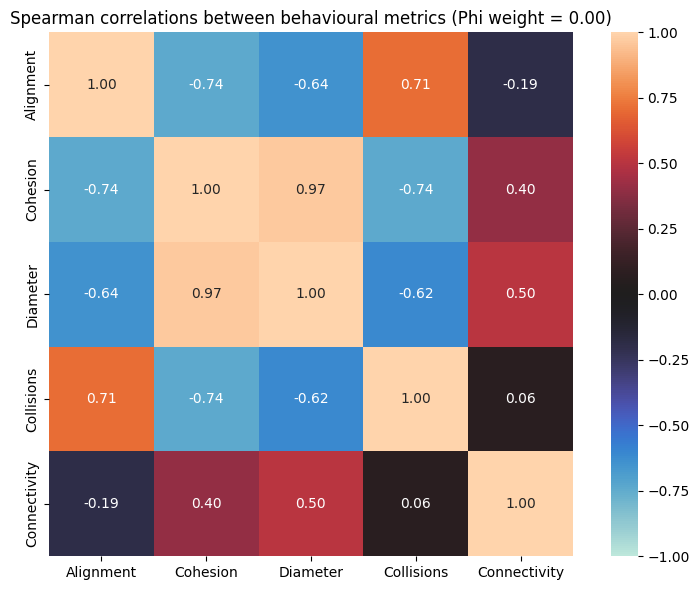

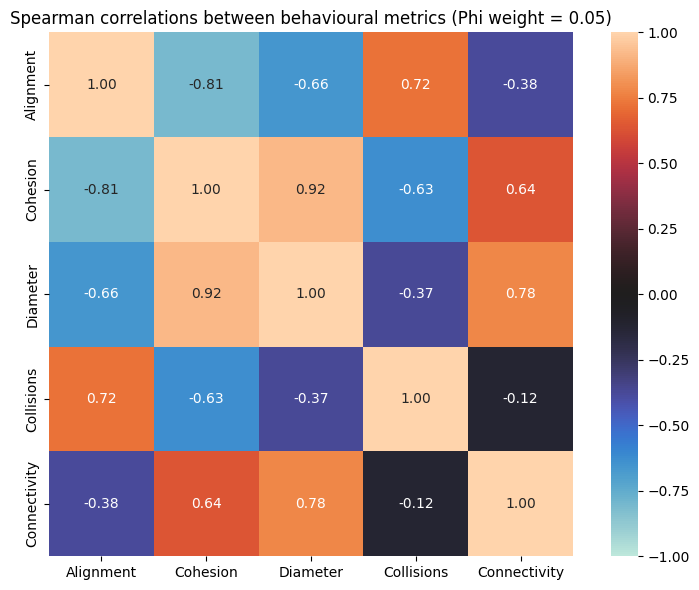

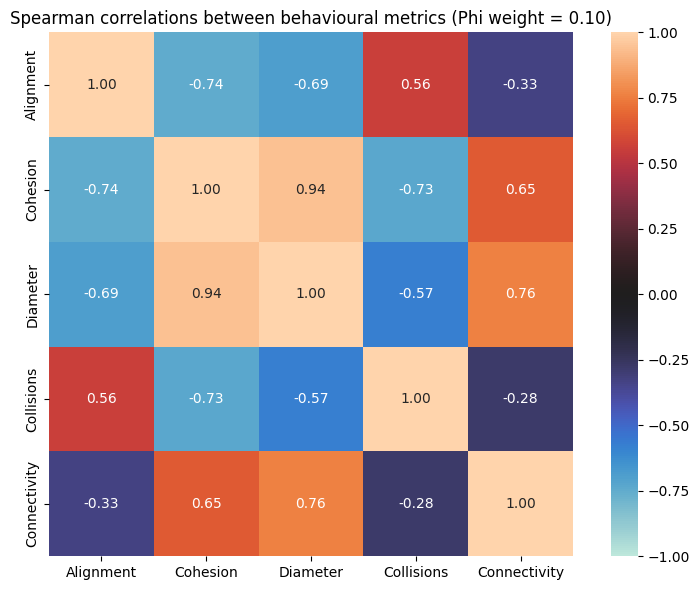

In [156]:
corranalysplot(data00, "Phi weight = 0.00")
corranalysplot(data05, "Phi weight = 0.05")
corranalysplot(data10, "Phi weight = 0.10")

In [157]:
dfs = []

for data, w in [(data00, 0.00), (data05, 0.05), (data10, 0.10)]:
    dfs.append(pd.DataFrame({
        "alignment": data["avg_alignm_after_100"],
        "cohesion": data["avg_cohesi_after_100"],
        "diameter": data["avg_diamet_after_100"],
        "collisions": data["avg_collis_after_100"],
        "connectivity": data["avg_connec_after_100"],
        "phi_weight": w,
    }))

comb = pd.concat(dfs, ignore_index=True)
behmetrs = ["alignment", "cohesion", "diameter", "collisions", "connectivity"]
print("\nSpearman correlation between behavioural metrics:")
print(comb[behmetrs].corr(method="spearman").round(3))


Spearman correlation between behavioural metrics:
              alignment  cohesion  diameter  collisions  connectivity
alignment         1.000    -0.830    -0.740       0.766        -0.416
cohesion         -0.830     1.000     0.943      -0.834         0.614
diameter         -0.740     0.943     1.000      -0.653         0.722
collisions        0.766    -0.834    -0.653       1.000        -0.286
connectivity     -0.416     0.614     0.722      -0.286         1.000


In [158]:
def corrtests(data, name):
    df = pd.DataFrame({
        "alignment": data["avg_alignm_after_100"],
        "cohesion": data["avg_cohesi_after_100"],
        "diameter": data["avg_diamet_after_100"],
        "collisions": data["avg_collis_after_100"],
        "connectivity": data["avg_connec_after_100"],
    })
    results = []
    for i, metr1 in enumerate(df.columns):
        for metr2 in df.columns[i+1:]:
            rho, p = stats.spearmanr(df[metr1], df[metr2])
            results.append({"condition": name, "metric_1": metr1, "metric_2": metr2, "rho": rho, "p_value": p})
    return pd.DataFrame(results)

In [159]:
print(pd.concat([corrtests(data00, "Phi = 0.00"), corrtests(data05, "Phi = 0.05"), corrtests(data10, "Phi = 0.10")]).round(4))

    condition    metric_1      metric_2     rho  p_value
0  Phi = 0.00   alignment      cohesion -0.7399   0.0000
1  Phi = 0.00   alignment      diameter -0.6445   0.0000
2  Phi = 0.00   alignment    collisions  0.7087   0.0000
3  Phi = 0.00   alignment  connectivity -0.1943   0.0528
4  Phi = 0.00    cohesion      diameter  0.9677   0.0000
5  Phi = 0.00    cohesion    collisions -0.7420   0.0000
6  Phi = 0.00    cohesion  connectivity  0.4012   0.0000
7  Phi = 0.00    diameter    collisions -0.6165   0.0000
8  Phi = 0.00    diameter  connectivity  0.5002   0.0000
9  Phi = 0.00  collisions  connectivity  0.0625   0.5366
0  Phi = 0.05   alignment      cohesion -0.8062   0.0000
1  Phi = 0.05   alignment      diameter -0.6568   0.0000
2  Phi = 0.05   alignment    collisions  0.7231   0.0000
3  Phi = 0.05   alignment  connectivity -0.3828   0.0001
4  Phi = 0.05    cohesion      diameter  0.9196   0.0000
5  Phi = 0.05    cohesion    collisions -0.6320   0.0000
6  Phi = 0.05    cohesion  conn